<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc

# 1. Generate Synthetic Bank Loan Data
np.random.seed(42)
n_samples = 1000

data = {
    'Age': np.random.randint(21, 65, size=n_samples),
    'Income': np.random.normal(70000, 25000, size=n_samples).astype(int),
    'CreditScore': np.random.randint(500, 850, size=n_samples),
    'DebtToIncomeRatio': np.random.uniform(0.1, 0.6, size=n_samples),
    'YearsWithEmployer': np.random.randint(0, 20, size=n_samples)
}

df = pd.DataFrame(data)

# Define logical rule for approval to guide target generation with some noise
# High credit score, high income, low debt ratio -> more likely to be approved
score = (df['CreditScore'] * 0.4) + (df['Income'] / 1000 * 0.4) - (df['DebtToIncomeRatio'] * 200)
threshold = score.median()
noise = np.random.normal(0, 50, size=n_samples)
df['LoanApproved'] = (score + noise > threshold).astype(int)

# Display preview of dataset
print("--- Dataset Preview ---")
display(df.head())
print(df.info())

--- Dataset Preview ---


,Age,Income,CreditScore,DebtToIncomeRatio,YearsWithEmployer,LoanApproved
0,59,47879,844,0.380437,2,1
1,49,77173,840,0.531981,7,0
2,35,74129,660,0.340667,2,0
3,63,84223,677,0.548837,7,0
4,28,48129,616,0.437174,17,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                1000 non-null   int64  
 1   Income             1000 non-null   int64  
 2   CreditScore        1000 non-null   int64  
 3   DebtToIncomeRatio  1000 non-null   float64
 4   YearsWithEmployer  1000 non-null   int64  
 5   LoanApproved       1000 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 47.0 KB
None


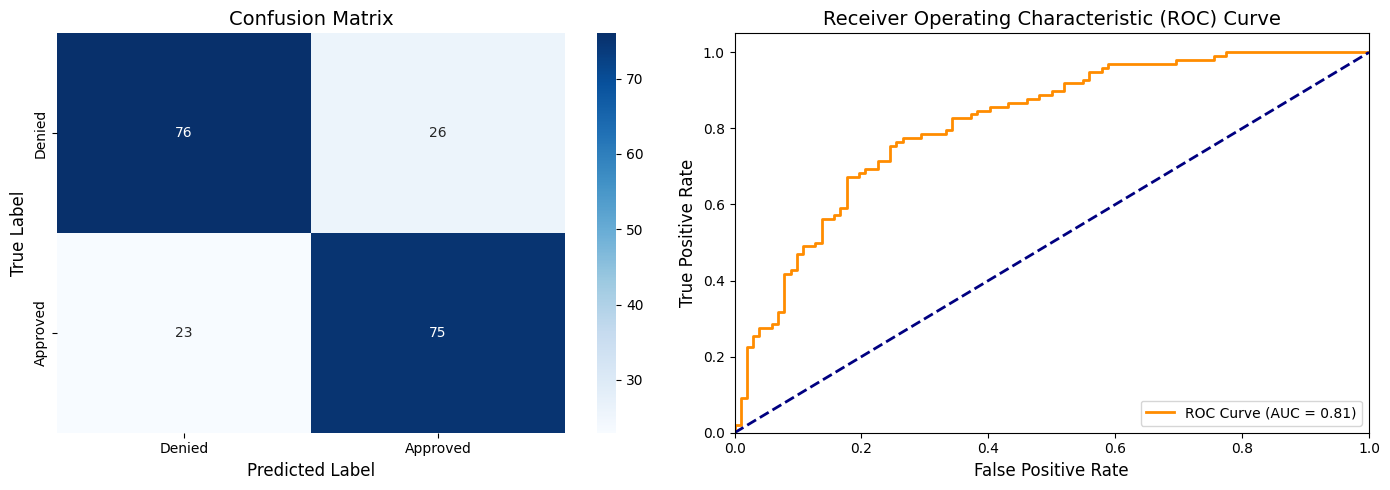

     NAIVE BAYES MODEL EVALUATION        
Model Accuracy: 75.50%

Classification Report:
              precision    recall  f1-score   support

      Denied       0.77      0.75      0.76       102
    Approved       0.74      0.77      0.75        98

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.75       200
weighted avg       0.76      0.76      0.76       200



In [2]:
# 2. Data Preprocessing & Splitting
X = df.drop(columns=['LoanApproved'])
y = df['LoanApproved']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features (recommended for presentable output/distribution consistency)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Training
model = GaussianNB()
model.fit(X_train_scaled, y_train)

# 4. Model Evaluation
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=['Denied', 'Approved'])
conf_matrix = confusion_matrix(y_test, y_pred)

# 5. Presentable Output Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Denied', 'Approved'], yticklabels=['Denied', 'Approved'], ax=axes[0])
axes[0].set_title('Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Print final performance metrics in a readable text block
print(f"=========================================")
print(f"     NAIVE BAYES MODEL EVALUATION        ")
print(f"=========================================")
print(f"Model Accuracy: {accuracy:.2%}\n")
print("Classification Report:")
print(report)
print(f"=========================================")